# Project Instructions

There are three sections of this project that you will need to complete. Below you will find directions to assist with each portion of this project.

## Data Description

In this portion of the presentation, you should describe at least the following aspects of the dataset:

- the number of employees that are in the dataset
- how missing data were handled
- the range of salaries
- any plots or estimates that suggest certain features in the dataset are likely correlated to salary

## Regression Results

In this portion of the presentation, you should

- share the regression output associated with your linear model
- identify which variables are statistically significant in their relationship with salary
- remove variables from the model that are not statistically significant
- identify how well the model fits the data

## Interpretation of Model Results
In this portion of the presentation, you should choose two variables in the model and provide:

- the expected range of change in salary related to changes in this variable
- how confident you are that these changes are likely to happen

Ex: We can be 95% confident that salary will increase between 10 and 20 dollars when moving from no title to a director title. (this example is for illustrative purposes only)

# Rubric
Use this project rubric to understand and assess the project criteria.

## Code Quality
|Criteria|Submission Requirements|
|--------|-----------------------|
|Functionality of code|All code cells can be run without error.|

## Statistical Analyses
|Criteria|Submission Requirements|
|--------|-----------------------|
|Data Preparation|Data preparation, including cleaning the dataframe and creating new variables, is performed correctly.|
|Correct Interpretation of Results|The interpretation of all results from different analyses is correct and includes both statistical reasoning and practical reasoning.|
|Correct Values for All Statistical Results|All statistical numeric values are calculated correctly. These include model coefficients and metrics associated with model fit.|

## Suggestions to Make Your Project Stand Out

- Expanded EDA
- Consider all assumptions of regression and the potential issues with any of them being violated.

# Salary Prediction

Corresponding  with this notebook is a slide deck where you will need to update all the portions in red.  Completing the notebook will provide all the results needed for the slides.  **Correctly completing the slides is a required part of the project.**


## Table of Contents
- [Introduction](#intro)
- [Part I - Descriptive Statistics](#descriptive)
- [Part II - Regression](#regression)
- [Part III - Interpret Results](#interpret)


<a id='intro'></a>
### Introduction

Linear Regression is very commonly performed by data analysts and data scientists.  For this project, you will be working to understand the results of a Linear Regression model associated with salaries.  Your goal is to work through this notebook to understand what variables are related to salary, and how exactly they are related.

As a final check, assure you meet all the criteria on the rubric.

<a id='descriptive'></a>
#### Part I - Descriptive Statistics

To get started, let's import our libraries.

In [22]:
import pandas as pd
import numpy as np
import random
import matplotlib.pyplot as plt
import statsmodels.api as sm
random.seed(0)

For each of the parts of question `1` notice links to [pandas documentation](https://pandas.pydata.org/) is provided to assist with answering the questions.  Though there are other ways you could solve the questions, the documentation is provided to assist you with one fast way to find the answer to each question.


`1.a)` Now, read in the `salary_data.csv` data. Store it in `df`. Read in the dataset and take a look at the top few rows here. **This question is completed for you**:

In [23]:
df = pd.read_csv('salary_data.csv')
df.head()

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0


`b)` Use the below cell to find the number of rows in the dataset. [Helpful pandas link - `Dataframe.shape`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.shape.html#pandas.DataFrame.shape)

In [24]:
df.shape

(375, 6)

`c)` Do any of the rows have missing values? [Helpful Pandas Link One](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.isnull.html) and [Helpful Pandas Link Two](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.sum.html)  

If there are missing values, determine a method for dealing with them.

In [25]:
df.isnull().sum()

Age                    2
Gender                 2
Education Level        2
Job Title              2
Years of Experience    2
Salary                 2
dtype: int64

In [26]:
df = df.dropna()
print(df.isnull().sum())

Age                    0
Gender                 0
Education Level        0
Job Title              0
Years of Experience    0
Salary                 0
dtype: int64


`d)` How many employees are in each `Education Level`? Build a bar chart to show the count of employees in each level.

In [27]:
df['Education Level'].value_counts()

Education Level
Bachelor's    224
Master's       98
PhD            51
Name: count, dtype: int64

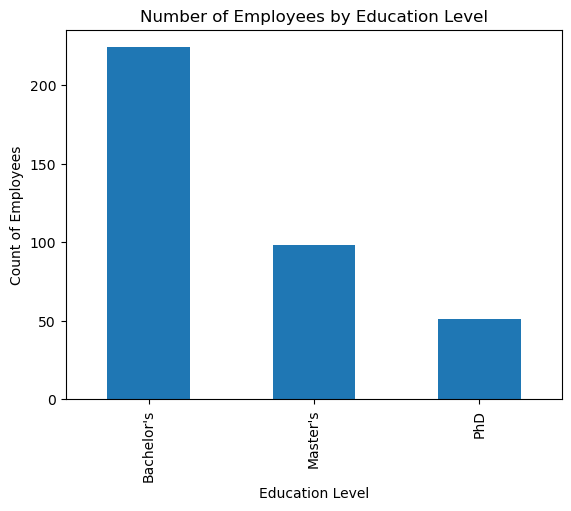

In [28]:
# bar chart of results - this part is done for you
df['Education Level'].value_counts().plot(kind='bar');
plt.title('Number of Employees by Education Level');
plt.ylabel('Count of Employees');
plt.show();

`e)` What are the possible values for `Salary`?  What does the distribution of `Salary` look like?

In [29]:
print(df['Salary'].describe())

count       373.000000
mean     100577.345845
std       48240.013482
min         350.000000
25%       55000.000000
50%       95000.000000
75%      140000.000000
max      250000.000000
Name: Salary, dtype: float64


The salaries range between $350 and $250,000, with an average of $100,577 and a median of $95,000.

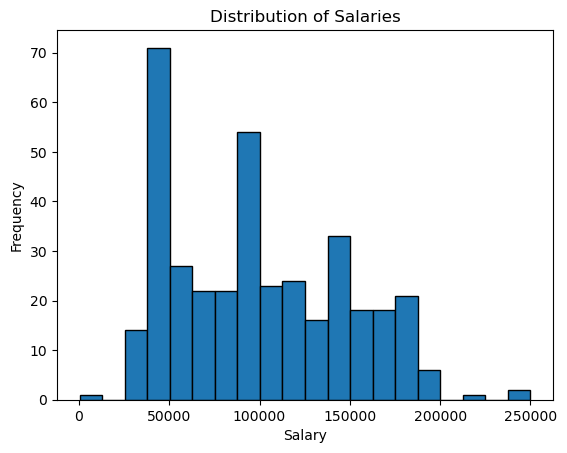

In [30]:
plt.hist(df['Salary'], bins=20, edgecolor='black')
plt.title('Distribution of Salaries')
plt.xlabel('Salary')
plt.ylabel('Frequency')
plt.show()

The distribution of salaries is multimodal, with distinct peaks around the $50,000, $100,000, and $150,000 marks. It is slightly right-skewed (the mean of $100,577 is higher than the median of $95,000). The most frequent salary bin appears to be around $50,000 with over 70 employees.

<a id='regression'></a>
#### Part II - Regression

`1.` Now that you have had a chance to learn more about the dataset, let's look more at how different factors are related to `Salary`.

`a)` Consider average salary by gender, is there evidence that salaries are higher for one gender over the other?

In [31]:
avg_salary_gender = df.groupby('Gender')['Salary'].mean().round(0)
print(f"Average salary by gender: female = {avg_salary_gender['Female']:.0f}, male = {avg_salary_gender['Male']:.0f}")

Average salary by gender: female = 97011, male = 103868


In [32]:
df_gender = pd.get_dummies(df[['Salary', 'Gender']], drop_first=True).astype(int)
df_gender['intercept'] = 1
print(df_gender.head())
gender_salary_linear_model = sm.OLS(df_gender['Salary'], df_gender[['intercept', 'Gender_Male']]).fit()
gender_salary_linear_model.summary()

   Salary  Gender_Male  intercept
0   90000            1          1
1   65000            0          1
2  150000            1          1
3   60000            0          1
4  200000            1          1


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Salary   R-squared:                       0.005
Model:                            OLS   Adj. R-squared:                  0.002
Method:                 Least Squares   F-statistic:                     1.885
Date:                Wed, 06 May 2026   Prob (F-statistic):              0.171
Time:                        07:29:42   Log-Likelihood:                -4550.2
No. Observations:                 373   AIC:                             9104.
Df Residuals:                     371   BIC:                             9112.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
===============================================================================
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
intercept    9.701e+04   3601.345     26.937      0.000    8.99e+04    1.04e+05
Gender_Male  6856.6103   4993.652      1.373      0.171   -2962.801    1.67e+04
==============================================================================
Omnibus:                       33.681   Durbin-Watson:                   2.882
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               18.404
Skew:                           0.383   Prob(JB):                     0.000101
Kurtosis:                       2.227   Cond. No.                         2.67
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

There is no statistically significant evidence that salaries are higher for one gender over the other.

Since the p-value (0.171) is greater than the standard alpha level of 0.05, we fail to reject the null hypothesis. This means that while a physical difference of ~$6,857 exists in this specific sample, it is not large enough given the spread of the data to conclude that a systematic salary gap exists across the broader population. The observed difference could likely be due to random chance or other factors like years of experience.

`b)` Consider average salary by education level, is there evidence that salaries are higher for increased education?

In [33]:
avg_salary_education = df.groupby('Education Level')['Salary'].mean().round(0)
print(f"Average salary by education level: {avg_salary_education}")

Average salary by education level: Education Level
Bachelor's     74756.0
Master's      129796.0
PhD           157843.0
Name: Salary, dtype: float64


In [34]:
df_education = pd.get_dummies(df[['Salary', 'Education Level']], drop_first=True).astype(int)
df_education['intercept'] = 1
print(df_education.head())
education_salary_linear_model = sm.OLS(df_education['Salary'], df_education[['intercept', 'Education Level_Master\'s', 'Education Level_PhD']]).fit()
education_salary_linear_model.summary()

   Salary  Education Level_Master's  Education Level_PhD  intercept
0   90000                         0                    0          1
1   65000                         1                    0          1
2  150000                         0                    1          1
3   60000                         0                    0          1
4  200000                         1                    0          1


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Salary   R-squared:                       0.462
Model:                            OLS   Adj. R-squared:                  0.459
Method:                 Least Squares   F-statistic:                     159.1
Date:                Wed, 06 May 2026   Prob (F-statistic):           1.38e-50
Time:                        07:29:42   Log-Likelihood:                -4435.4
No. Observations:                 373   AIC:                             8877.
Df Residuals:                     370   BIC:                             8889.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
============================================================================================
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
intercept                 7.476e+04   2369.718     31.546      0.000    7.01e+04    7.94e+04
Education Level_Master's  5.504e+04   4295.479     12.813      0.000    4.66e+04    6.35e+04
Education Level_PhD       8.309e+04   5502.727     15.099      0.000    7.23e+04    9.39e+04
==============================================================================
Omnibus:                       27.739   Durbin-Watson:                   2.618
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               34.532
Skew:                           0.603   Prob(JB):                     3.17e-08
Kurtosis:                       3.877   Cond. No.                         3.35
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

There is a clear upward trend in salary as education levels increase:
- Bachelor's: $74,756
  
- Master's: $129,796

- PhD: $157,843

There is strong statistically significant evidence that higher education levels are associated with higher salaries. Because the p-values are well below the 0.05 threshold, we can reject the null hypothesis and conclude that education is a major predictor of salary in this dataset.

`c)` Consider average salary by years of experience, is there evidence that salaries are associated with increased years of experience?

In [35]:
avg_salary_experience = df.groupby('Years of Experience')['Salary'].mean().round(0)
print(f"Average salary by years of experience: {avg_salary_experience}")

Average salary by years of experience: Years of Experience
0.0      33333.0
0.5      35000.0
1.0      37857.0
1.5      36279.0
2.0      41774.0
3.0      51167.0
4.0      58500.0
5.0      64118.0
6.0      83750.0
7.0      84444.0
8.0      88800.0
9.0     101818.0
10.0    100556.0
11.0    100500.0
12.0    105000.0
13.0    120000.0
14.0    125769.0
15.0    134375.0
16.0    157500.0
17.0    143000.0
18.0    149615.0
19.0    166333.0
20.0    168846.0
21.0    173846.0
22.0    162222.0
23.0    177500.0
24.0    250000.0
25.0    200000.0
Name: Salary, dtype: float64


In [36]:
df_experience = df[['Salary', 'Years of Experience']]
df_experience['intercept'] = 1
print(df_experience.head())
experience_salary_linear_model = sm.OLS(df_experience['Salary'], df_experience[['intercept', 'Years of Experience']]).fit()
experience_salary_linear_model.summary()

     Salary  Years of Experience  intercept
0   90000.0                  5.0          1
1   65000.0                  3.0          1
2  150000.0                 15.0          1
3   60000.0                  7.0          1
4  200000.0                 20.0          1


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Salary   R-squared:                       0.866
Model:                            OLS   Adj. R-squared:                  0.865
Method:                 Least Squares   F-statistic:                     2388.
Date:                Wed, 06 May 2026   Prob (F-statistic):          1.02e-163
Time:                        07:29:42   Log-Likelihood:                -4177.0
No. Observations:                 373   AIC:                             8358.
Df Residuals:                     371   BIC:                             8366.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
=======================================================================================
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
intercept            3.192e+04   1677.842     19.025      0.000    2.86e+04    3.52e+04
Years of Experience  6844.5105    140.065     48.867      0.000    6569.089    7119.932
==============================================================================
Omnibus:                       42.211   Durbin-Watson:                   1.862
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              119.478
Skew:                          -0.511   Prob(JB):                     1.14e-26
Kurtosis:                       5.577   Cond. No.                         22.0
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

There is overwhelmingly strong statistically significant evidence that salary is positively associated with years of experience. The model suggests that experience is the strongest individual predictor of salary among the variables tested so far.

`d)`  To make use of Job Title column lets create bool flag based on word existiance


List of words:

* Director
* Junior
* Senior
* Manager
* Analyst
* Engineer

**This question is completed for you**

In [37]:
flag_words = ['director', 'junior', 'senior', 'manager', 'analyst', 'engineer']
df['Job Title'] = df['Job Title'].str.lower()

for word in flag_words:
    df['is_' + word] = df['Job Title'].str.contains(word)
    
df = df.drop('Job Title', axis=1)

`e)` Create a flag for gender where 1 is if a person is male and 0 if the person is not.

In [38]:
df['is_male'] = (df['Gender'] == 'Male').astype(int)
df.head()

,Age,Gender,Education Level,Years of Experience,Salary,is_director,is_junior,is_senior,is_manager,is_analyst,is_engineer,is_male
0,32.0,Male,Bachelor's,5.0,90000.0,False,False,False,False,False,True,1
1,28.0,Female,Master's,3.0,65000.0,False,False,False,False,True,False,0
2,45.0,Male,PhD,15.0,150000.0,False,False,True,True,False,False,1
3,36.0,Female,Bachelor's,7.0,60000.0,False,False,False,False,False,False,0
4,52.0,Male,Master's,20.0,200000.0,True,False,False,False,False,False,1


`f)` Use statsmodels to fit a linear model to predict salary using each of the features from `a-e`.  These include:
* Gender
* Job TItle
* Years of Experience
* Education

In [39]:
df['intercept'] = 1
df[['has_bachelors', 'has_masters', 'has_phd']] = pd.get_dummies(df['Education Level'], drop_first=False).astype(int)
cols_to_transform = ['is_engineer', 'is_analyst', 'is_manager', 'is_senior', 'is_junior', 'is_director']
df[cols_to_transform] = df[cols_to_transform].astype(int)
y = df['Salary']
X = df[['intercept', 'is_male', 'Years of Experience', 'has_masters', 'has_phd', 'is_engineer', 'is_analyst', 'is_manager', 'is_senior', 'is_junior', 'is_director']]
print(y)
print(X)

linear_model = sm.OLS(y, X).fit()
linear_model.summary()

0       90000.0
1       65000.0
2      150000.0
3       60000.0
4      200000.0
         ...   
370     85000.0
371    170000.0
372     40000.0
373     90000.0
374    150000.0
Name: Salary, Length: 373, dtype: float64
     intercept  is_male  Years of Experience  has_masters  has_phd  \
0            1        1                  5.0            0        0   
1            1        0                  3.0            1        0   
2            1        1                 15.0            0        1   
3            1        0                  7.0            0        0   
4            1        1                 20.0            1        0   
..         ...      ...                  ...          ...      ...   
370          1        0                  8.0            0        0   
371          1        1                 19.0            1        0   
372          1        0                  2.0            0        0   
373          1        1                  7.0            0        0   
374         

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Salary   R-squared:                       0.915
Model:                            OLS   Adj. R-squared:                  0.913
Method:                 Least Squares   F-statistic:                     391.7
Date:                Wed, 06 May 2026   Prob (F-statistic):          2.41e-187
Time:                        07:29:42   Log-Likelihood:                -4090.6
No. Observations:                 373   AIC:                             8203.
Df Residuals:                     362   BIC:                             8246.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
=======================================================================================
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
intercept            3.212e+04   2485.604     12.921      0.000    2.72e+04     3.7e+04
is_male              7484.7304   1509.904      4.957      0.000    4515.446    1.05e+04
Years of Experience  4937.4278    197.548     24.994      0.000    4548.941    5325.914
has_masters          1.345e+04   2053.896      6.547      0.000    9408.638    1.75e+04
has_phd              2.327e+04   2801.927      8.304      0.000    1.78e+04    2.88e+04
is_engineer          2362.9515   3561.972      0.663      0.508   -4641.805    9367.708
is_analyst           -176.3409   2103.878     -0.084      0.933   -4313.698    3961.016
is_manager           4434.5081   1960.352      2.262      0.024     579.400    8289.617
is_senior            1.307e+04   1976.833      6.610      0.000    9178.417     1.7e+04
is_junior           -4492.5634   2458.516     -1.827      0.068   -9327.330     342.203
is_director          2.539e+04   3535.194      7.181      0.000    1.84e+04    3.23e+04
==============================================================================
Omnibus:                      130.784   Durbin-Watson:                   1.815
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1091.992
Skew:                           1.230   Prob(JB):                    7.53e-238
Kurtosis:                      11.013   Cond. No.                         63.1
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

<a id='interpretation'></a>
### Part III - Interpret Results

`1.` Consider you are tasked with finding which features in your linear model are significantly related to salary.  Were there any features that were not significantly related to salary in your first model?  If not, remove those features and fit a new model.  Only keep the features that were significant from the original model.

Explain your answer and fit a new model with the reduced set of features here

The following features were not significant related to salary as their corresponding p-value is greater than the 0.05 threshold:

- is_engineer: p-value = 0.508 (Not Significant)
- is_analyst: p-value = 0.933 (Not Significant)
- is_junior: p-value = 0.068 (Not Significant)

In [40]:
significant_cols = [
    'intercept', 
    'is_male', 
    'Years of Experience', 
    'has_masters', 
    'has_phd', 
    'is_manager', 
    'is_senior', 
    'is_director'
]

X_reduced = df[significant_cols]
linear_model_reduced = sm.OLS(y, X_reduced).fit()
linear_model_reduced.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Salary   R-squared:                       0.914
Model:                            OLS   Adj. R-squared:                  0.913
Method:                 Least Squares   F-statistic:                     557.4
Date:                Wed, 06 May 2026   Prob (F-statistic):          1.46e-190
Time:                        07:29:42   Log-Likelihood:                -4092.6
No. Observations:                 373   AIC:                             8201.
Df Residuals:                     365   BIC:                             8233.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
=======================================================================================
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
intercept            2.876e+04   1677.411     17.146      0.000    2.55e+04    3.21e+04
is_male              7629.6521   1481.834      5.149      0.000    4715.649    1.05e+04
Years of Experience  5104.4388    177.226     28.802      0.000    4755.927    5452.950
has_masters          1.404e+04   2032.078      6.908      0.000       1e+04     1.8e+04
has_phd              2.308e+04   2760.740      8.360      0.000    1.77e+04    2.85e+04
is_manager           4284.6595   1822.582      2.351      0.019     700.579    7868.740
is_senior            1.445e+04   1820.427      7.936      0.000    1.09e+04     1.8e+04
is_director          2.498e+04   3503.028      7.131      0.000    1.81e+04    3.19e+04
==============================================================================
Omnibus:                      126.635   Durbin-Watson:                   1.790
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1010.895
Skew:                           1.196   Prob(JB):                    3.07e-220
Kurtosis:                      10.702   Cond. No.                         60.8
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

`a)` With each additional year of experience, what is the expected change in salary?  What is the 95% confidence interval of the change?

**Your Answer Here**

For each additional year of experience, the expected change in salary is $5,104.44.

The 95% confidence interval of the change is between 4,755.93 and 5,452.95 dollars.

`b)` What is the expected difference in salary between someone with a senior title and someone with none of the other title indications?

**Your Answer Here**

The expected salary difference between a senior and someone with none of the other titles is $14,450.

`c)` What is the expected difference in salary between someone with a PhD and an individual with no PhD nor master's degree?  What is the 95% confidence interval of the change?

**Your Answer Here**

The expected difference in salary between someone with a PhD and an individual with no PhD nor master's degree is $23,080.

The 95% confidence interval of the change is between 17,700 and 28,500 dollars.

`d)` If a male employee has 5 years of experience as a senior engineer with a bachelor's degree, what is the expected salary of the employee?

**Your Answer Here**

If a male employee has 5 years of experience as a senior engineer with a bachelor's degree, his expected salary is $76,359.11.

This is calculated as follows: 

Intercept: $28,760

Male: $7,630

Years of experience: 5 × 5,104.44 = 25,522.20 dollars

Senior: $14,450

Total = 28,760.78 + 7,629.65 + (5 * 5,104.44) + 14,446.48 = $76,359.11

Note that the engineer title does not add a separate amount in the reduced model because `is_engineer` was removed after it was determined to be not statistically significant in the initial model.

`e)` Imagine that the employee in question `d)` actually has a salary of $110,000, what would the residual be for this employee?

**Your Answer Here**

Residual = Actual - Predicted

Residual = 110,000 - 76,359.11

Residual = $33,640.89

`f)` How well do you think your model fits?  What metrics or plots would you consider to understand if this model does a good job of predicting salary?

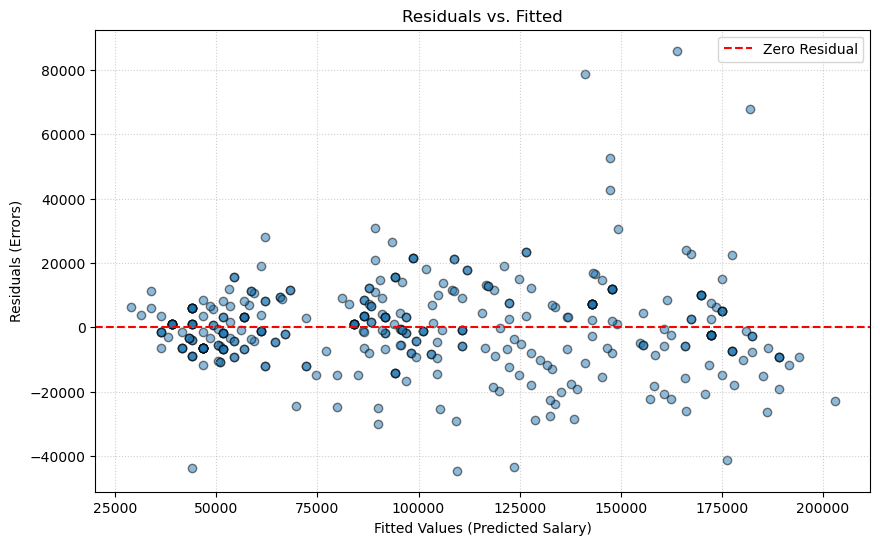

In [41]:
### Your work here

fitted_values = linear_model_reduced.fittedvalues
residuals = linear_model_reduced.resid

plt.figure(figsize=(10, 6))
plt.scatter(fitted_values, residuals, alpha=0.5, edgecolors='k')

plt.axhline(y=0, color='r', linestyle='--', label='Zero Residual')

plt.xlabel('Fitted Values (Predicted Salary)')
plt.ylabel('Residuals (Errors)')
plt.title('Residuals vs. Fitted')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)

plt.show()

**Your Answer Here**

Based on an $R^2$ of 0.914, which is exceptionally high, the model fits really well. The $R^2$ suggests that 91.4% of the variance in salary is explained by the regression model. 

Beyond $R^2$, we can look at a plot of residuals versus fitted. This plot helps verify if the relationship between salary and independent variables like experience and education is actually linear.

The residuals vs. fitted plot suggests the linearity assumption is reasonably plausible because the residuals are centered around zero without a strong curved pattern. However, the model output shows residual non-normality, with skew = 1.196 and kurtosis = 10.702, likely due to a few large outliers. So the model has strong explanatory power with $R^2$ = 0.914, but I would be cautious about claiming it fully satisfies all regression assumptions.